# Cleaning epoched data

In [1]:
# setup
import pathlib
import matplotlib

import mne
import mne_bids

matplotlib.use('QtAgg')
mne.set_log_level('warning')

In [2]:
epochs = mne.read_epochs(pathlib.Path('out_data') / 'epochs_epo.fif')
print(epochs)

<EpochsFIF | 320 events (all good), -0.25 – 0.799 s (baseline -0.2 – 0 s), ~579.6 MiB, data loaded,
 'Auditory/Left': 72
 'Auditory/Right': 73
 'Button': 16
 'Smiley': 15
 'Visual/Left': 73
 'Visual/Right': 71>


In [3]:
# apply a baseline as in prev notebook we choose baseline from (-0.20,0) not the entire
print(epochs.apply_baseline((None, 0)))

<EpochsFIF | 320 events (all good), -0.25 – 0.799 s (baseline -0.25 – 0 s), ~579.6 MiB, data loaded,
 'Auditory/Left': 72
 'Auditory/Right': 73
 'Button': 16
 'Smiley': 15
 'Visual/Left': 73
 'Visual/Right': 71>


In [4]:
epochs.info

<Info | 22 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: 2 items (MEG 2443, EEG 053)
 ch_names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG ...
 chs: 204 Gradiometers, 102 Magnetometers, 9 Stimulus, 60 EEG, 1 EOG
 custom_ref_applied: False
 description: Anonymized using a time shift to preserve age at acquisition
 dev_head_t: MEG device -> head transform
 dig: 146 items (3 Cardinal, 4 HPI, 61 EEG, 78 Extra)
 events: 1 item (list)
 experimenter: mne_anonymize
 file_id: 4 items (dict)
 highpass: 0.1 Hz
 hpi_results: 1 item (list)
 line_freq: 60.0
 lowpass: 40.0 Hz
 meas_date: 2002-12-03 19:01:10 UTC
 meas_id: 4 items (dict)
 nchan: 376
 proj_id: 0
 proj_name: mne_anonymize
 projs: PCA-v1: on, PCA-v2: on, PCA-v3: on
 sfreq: 600.6 Hz
 subject_info: <subject_info | his_id: sub-01, birthday: 1988-12-02, sex: 1, hand: 3>
>

In [5]:
epochs.plot()

# Reject artifacts based on channel signal amplitude

In [6]:
#specifing rejection criteria
reject_criteria = dict(
    mag = 3000e-15, # 3000 fT
    grad =3000e-13, # 3000 fT/cm
    eeg=150e-6,     # 150 micro Volt
    eog=200e-6)     # 200 micro volt


flat_criteria = dict(
    mag = 1e-15, # 1fT
    grad =1e-13, # 1 fT/cm
    eeg=1e-6,     # 1 micro Volt
    ) 

In [7]:
epochs.drop_bad(reject=reject_criteria, flat=flat_criteria)

<EpochsFIF | 251 events (all good), -0.25 – 0.799 s (baseline -0.25 – 0 s), ~454.7 MiB, data loaded,
 'Auditory/Left': 52
 'Auditory/Right': 59
 'Button': 14
 'Smiley': 12
 'Visual/Left': 59
 'Visual/Right': 55>

In [8]:
epochs.plot_drop_log()

<Figure size 800x600 with 1 Axes>

Quite a number of Epochs were dropped due to EOG artifacts

In [27]:
epochs['Visual'].plot_image()

[<Figure size 800x600 with 3 Axes>,
 <Figure size 800x600 with 3 Axes>,
 <Figure size 800x600 with 3 Axes>]

In [30]:
epochs.plot_sensors(ch_type='eeg')

<Figure size 800x800 with 1 Axes>

In [ ]:
# visual cortex
epochs['Visual'].plot_image(picks='EEG 060')

[<Figure size 800x600 with 4 Axes>]

# SSP

## Let's see if we can retain most the epochs, but still get rid of the EOG artifact. And while we're at it,the ECG artifacts too 

(think of it as it is a way to remove blinking artifact for example from our epoch without having to remove the entire epoch)

In [9]:
## ssp is techunique used with meg data 
## -it use pca-
bids_root = pathlib.Path('out_data/sample_BIDS')

bids_path = mne_bids.BIDSPath(
    subject='01',
    session='01',
    task='audiovisual',
    run='01',
    datatype='meg',
    root=bids_root)

raw = mne_bids.read_raw_bids(bids_path=bids_path)
raw.load_data()
raw.filter(l_freq=0.1, h_freq=40)

# Calculate projectors for heartbeat artifacts
ecg_projs, ecg_events = mne.preprocessing.compute_proj_ecg(raw=raw,
                                                           n_grad=1,
                                                           n_mag=1,
                                                           n_eeg=0,
                                                           average=True)


# Calculate projectors for eye-blink artifacts
eog_projs, eog_events = mne.preprocessing.compute_proj_eog(raw=raw,
                                                           n_grad=1,
                                                           n_mag=1,
                                                           n_eeg=1,
                                                           average=True)

In [10]:
ecg_projs

[<Projection | PCA-v1, active : False, n_channels : 102>,
 <Projection | PCA-v2, active : False, n_channels : 102>,
 <Projection | PCA-v3, active : False, n_channels : 102>,
 <Projection | ECG-planar--0.200-0.400-PCA-01, active : False, n_channels : 203, exp. var : 78.55%>,
 <Projection | ECG-axial--0.200-0.400-PCA-01, active : False, n_channels : 102, exp. var : 94.80%>]

In [11]:
eog_projs

[<Projection | PCA-v1, active : False, n_channels : 102>,
 <Projection | PCA-v2, active : False, n_channels : 102>,
 <Projection | PCA-v3, active : False, n_channels : 102>,
 <Projection | EOG-planar--0.200-0.200-PCA-01, active : False, n_channels : 203, exp. var : 92.61%>,
 <Projection | EOG-axial--0.200-0.200-PCA-01, active : False, n_channels : 102, exp. var : 88.38%>,
 <Projection | EOG-eeg--0.200-0.200-PCA-01, active : False, n_channels : 59, exp. var : 98.97%>]

In [12]:
projs = eog_projs + ecg_projs
projs

[<Projection | PCA-v1, active : False, n_channels : 102>,
 <Projection | PCA-v2, active : False, n_channels : 102>,
 <Projection | PCA-v3, active : False, n_channels : 102>,
 <Projection | EOG-planar--0.200-0.200-PCA-01, active : False, n_channels : 203, exp. var : 92.61%>,
 <Projection | EOG-axial--0.200-0.200-PCA-01, active : False, n_channels : 102, exp. var : 88.38%>,
 <Projection | EOG-eeg--0.200-0.200-PCA-01, active : False, n_channels : 59, exp. var : 98.97%>,
 <Projection | PCA-v1, active : False, n_channels : 102>,
 <Projection | PCA-v2, active : False, n_channels : 102>,
 <Projection | PCA-v3, active : False, n_channels : 102>,
 <Projection | ECG-planar--0.200-0.400-PCA-01, active : False, n_channels : 203, exp. var : 78.55%>,
 <Projection | ECG-axial--0.200-0.400-PCA-01, active : False, n_channels : 102, exp. var : 94.80%>]

In [13]:
epochs.add_proj(projs)
epochs.plot()

In [14]:
epochs_cleaned = epochs.copy().apply_proj()

epochs_cleaned['Visual'].plot_image()
epochs_cleaned['Visual'].plot_image(picks='EEG 060')

AttributeError: 'BrowserParams' object has no attribute 'keyboard_shortcuts'

[<Figure size 800x600 with 4 Axes>]

##### Note: Artifact cleaning involves a trade-off: reduce artifacts while preserving brain signals and enough trials. Non-stimulus-locked cardiac artifacts may decrease through evoked averaging, but this is not guaranteed. Compare responses and baseline noise before and after SSP; a cleaner-looking signal alone does not prove better data. Resting-state analyses require particular care because physiological differences between groups can confound the results. 

Side question: Is it possible an epoch data is already pre-processed with another software? 'Yes'  with read epoch eeglab link(https://mne.tools/stable/generated/mne.read_epochs_eeglab.html)

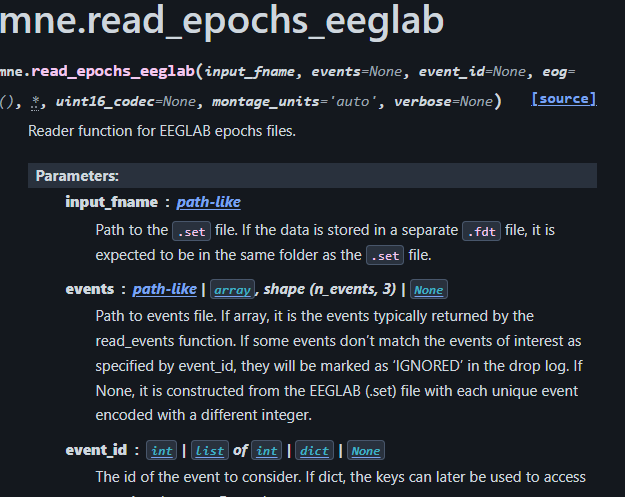

# ICA
First, start with the raw data again and apply, a 1.0 Hz high-pass filter, which is advantegeous for ICA performance

In [15]:
bids_root = pathlib.Path('out_data/sample_BIDS')

bids_path = mne_bids.BIDSPath(
    subject='01',
    session='01',
    task='audiovisual',
    run='01',
    datatype='meg',
    root=bids_root)

raw = mne_bids.read_raw_bids(bids_path=bids_path)
raw.load_data()
raw.filter(l_freq=1, h_freq=40) # High-pass whit 1. Hz Low-pass 40 Hz cut-off is recommended for ICA

<Raw | sub-01_ses-01_task-audiovisual_run-01_meg.fif, 376 x 166800 (277.7 s), ~478.9 MiB, data loaded>

Read our epochs and extract which ones that were kept (all in our case, because we didn't apply any rejection procedure before saving the epochs in notebook 3; but this could be different in a real-world scenario, and you want to calculate ICA on the same set of epochs you're actually feeding into you analyis)

In [16]:
epochs  = mne.read_epochs(pathlib.Path('out_data') / 'epochs_epo.fif')
epochs_selection = epochs.selection
epochs_selection

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

In [17]:
events, event_id = mne.events_from_annotations(raw)
events[:10][:], events.shape

(array([[27977,     0,     2],
        [28345,     0,     5],
        [28771,     0,     1],
        [29219,     0,     6],
        [29652,     0,     2],
        [30025,     0,     5],
        [30450,     0,     1],
        [30839,     0,     6],
        [31240,     0,     2],
        [31665,     0,     5]]),
 (320, 3))

In [18]:
events = events[epochs_selection]
events.shape,f"as we select all"

((320, 3), 'as we select all')

Create epochs for ICS, All parameters should match exactly the one of the epochs we intend to clean

In [19]:
tmin = epochs.tmin
tmax = epochs.tmax
baseline=epochs.baseline
print(f"tmin:{tmin},tmax:{tmax}\nwhy epochs.tmin/tmax as it contains the exact tmin and max of the epoch")
epochs_ica = mne.Epochs(
    raw=raw,
    events=events,
    event_id=event_id,
    tmin=tmin,
    tmax=tmax,
    baseline=baseline,
    preload=True
)

tmin:-0.24974401644798483,tmax:0.7991808526335514
why epochs.tmin/tmax as it contains the exact tmin and max of the epoch


In [ ]:
epochs_ica.info

<Info | 22 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: 2 items (MEG 2443, EEG 053)
 ch_names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG ...
 chs: 204 Gradiometers, 102 Magnetometers, 9 Stimulus, 60 EEG, 1 EOG
 custom_ref_applied: False
 description: Anonymized using a time shift to preserve age at acquisition
 dev_head_t: MEG device -> head transform
 dig: 146 items (3 Cardinal, 4 HPI, 61 EEG, 78 Extra)
 events: 1 item (list)
 experimenter: mne_anonymize
 file_id: 4 items (dict)
 highpass: 0.1 Hz
 hpi_results: 1 item (list)
 line_freq: 60.0
 lowpass: 40.0 Hz
 meas_date: 2002-12-03 19:01:10 UTC
 meas_id: 4 items (dict)
 nchan: 376
 proj_id: 0
 proj_name: mne_anonymize
 projs: PCA-v1: on, PCA-v2: on, PCA-v3: on
 sfreq: 600.6 Hz
 subject_info: <subject_info | his_id: sub-01, birthday: 1988-12-02, sex: 1, hand: 3>
>


In [21]:
# ICA bey7awel yefsel el signals el makhloota le components,
# 3ashan ne2dar ne7added artifacts zay eye blinks.

# Da threshold lel explained variance, MSH 3adad components.
# 0.8: MNE yekhtar a2al 3adad PCA components yeghati >80% men el variance,
# w yestakhdemhom fe ICA.

# 0.999: yeghati >99.9%, fa ghaleban yestakhdem components aktar.
# Aktar components = tafaseel aktar lel ICA, bas computation aktar.
# El variance hena feha brain activity W artifacts; mesh accuracy!
n_components = 0.8

# El algorithm elly haye7seb el ICA.
# Picard algorithm saree3 nesbeyan le fasl el components.
method = 'picard'

# Momken ye2af abl 100 law el solution "converged".
# Law 100 mesh kafya, momken ye2af abl ma yewsal le convergence.
# 500 aw 1000 yeddo forsah le khatwat aktar law me7tag.
# Mesh ma3nah enno LAZEM ye3mel kol el iterations de.
max_iter = 100

# Extra settings beneb3atha lel Picard algorithm.
# fastica_it=5: ye3mel 5 FastICA iterations ka bedaya,
# ba3dein yekammel bel Picard.
# Dol mesh 3adad components.
fit_params = dict(fastica_it=5)

random_state = 42

ica = mne.preprocessing.ICA(
    n_components=n_components,
    method=method,
    max_iter=max_iter,
    fit_params=fit_params,
    random_state=random_state
)

ica.fit(epochs_ica)

C:\Users\Zakaria\AppData\Local\Temp\ipykernel_5872\4197899557.py:39: RuntimeWarning: The epochs you passed to ICA.fit() were baseline-corrected. However, we suggest to fit ICA only on data that has been high-pass filtered, but NOT baseline-corrected.
  ica.fit(epochs_ica)
c:\Users\Zakaria\Downloads\eeg_study\eeg-signal-processing\.venv\Lib\site-packages\picard\solver.py:219: UserWarning: Picard did not converge. Final gradient norm : 8.074e-05. Requested tolerance : 1e-07. Consider increasing the number of iterations or the tolerance.
  warnings.warn('Picard did not converge. Final gradient norm : %.4g.'


Method,picard
Fit parameters,fastica_it=5max_iter=100
Fit,100 iterations on epochs (201920 samples)
ICA components,28
Available PCA components,364
Channel types,"mag, grad, eeg"
ICA components marked for exclusion,—


In [22]:
ica.plot_components(inst=epochs)

[<MNEFigure size 1002.5x726.25 with 20 Axes>,
 <MNEFigure size 1218.75x620 with 8 Axes>]

# Detect ECG and EOG patterns

In [ ]:
ecg_epochs = mne.preprocessing.create_ecg_epochs(raw, 
                                                 reject=None,
                                                 baseline=(None, -0.2),
                                                 tmin=-0.5, 
                                                 tmax=0.5)


ecg_evoked = ecg_epochs.average()
ecg_inds, ecg_scores = ica.find_bads_ecg(ecg_epochs, method='ctps')


eog_epochs = mne.preprocessing.create_eog_epochs(raw, 
                                                reject=None,
                                                baseline=(None, -0.2),
                                                tmin=-0.5, 
                                                tmax=0.5)

eog_evoked = eog_epochs.average()
eog_inds, eog_scores = ica.find_bads_eog(
    eog_epochs)

components_to_exclude = ecg_inds + eog_inds
ica.exclude = components_to_exclude

In [39]:
eog_epochs.plot();ecg_epochs.plot();epochs.plot()

In [25]:
ica.exclude

[np.int64(1), np.int64(15), np.int64(0)]

# Plot automated artifact detection scores

In [ ]:
# ica.plot_scores(ecg_scores)
ica.plot_scores(eog_scores)


<Figure size 800x337.5 with 1 Axes>

# Plot ICA sources

In [36]:
# ica.plot_sources(ecg_evoked,title="ecg_evoced")
ica.plot_sources(eog_evoked,title="eog_evoced")

<Figure size 800x600 with 1 Axes>

# Plot overlay of original and cleaned data

In [41]:
ica.plot_overlay(eog_evoked)

C:\Users\Zakaria\AppData\Local\Temp\ipykernel_5872\3418402708.py:1: RuntimeWarning: The data you passed to ICA.apply() was baseline-corrected. Please note that ICA can introduce DC shifts, therefore you may wish to consider baseline-correcting the cleaned data again.
  ica.plot_overlay(eog_evoked)


<Figure size 800x600 with 3 Axes>

* Visualize artifact detection scores, ICA sources, and an overlay of original and cleaned data based on the EOG epochs.

* Visualize artifact detection scores, ICA sources, and an overlay of original and cleaned data based on the epochs we actually intend to analyze.

In [47]:
# ica.apply?

In [45]:
cleaned = ica.apply(epochs.copy())

C:\Users\Zakaria\AppData\Local\Temp\ipykernel_5872\2194303672.py:1: RuntimeWarning: The data you passed to ICA.apply() was baseline-corrected. Please note that ICA can introduce DC shifts, therefore you may wish to consider baseline-correcting the cleaned data again.
  cleaned = ica.apply(epochs.copy())


In [46]:
cleaned.plot(title="cleaned");epochs.plot(title="uncleaned")

Note:

> **Muscle and other artifacts**
>
> We can automatically detect and annotate time segments containing muscle artifacts using `mne.preprocessing.annotate_muscle_zscore()`. This marks contaminated segments; it does not remove the muscle activity itself.  
> [MNE example: Annotate muscle artifacts](https://mne.tools/stable/auto_examples/preprocessing/muscle_detection.html). [MNE 1.13.2 documentation](https://mne.tools/stable/auto_examples/preprocessing/muscle_detection.html?utm_source=chatgpt.com)
>
> ICA can also help reduce muscle artifacts when they are separated into identifiable components. MNE provides `ica.find_bads_muscle()` to suggest muscle-related components, which should be reviewed before exclusion. [MNE 1.13.2 documentation](https://mne.tools/stable/generated/mne.preprocessing.ICA.html?utm_source=chatgpt.com)
>
> Other artifacts may require automatic methods, manual inspection, or both, depending on their type. Remaining contaminated segments or bad channels can be marked manually.

# Save Cleaned Data

In [ ]:
# cleaned.save("....")